In [1]:
!nvidia-smi

Wed Aug 26 11:44:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 596.08                 Driver Version: 596.08         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Quadro T2000                 WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   55C    P0             11W /   30W |       0MiB /   4096MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report, confusion_matrix

In [3]:


IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_dir = r"D:\ml project\brisc2025\classification_task\train"
val_dir   = r"D:\ml project\brisc2025\classification_task\test"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="categorical",   # one-hot, since we have 4 classes
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
print("Classes:", class_names)

# Prefetch for performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 5000 files belonging to 4 classes.
Found 1000 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [4]:
# load the dataset
train_ds = keras.utils.image_dataset_from_directory(
    "data/train",
    labels="inferred",
    label_mode="categorical",
    image_size=(224, 224),
    batch_size=32,
)
val_ds = keras.utils.image_dataset_from_directory(
    "data/test",
    labels="inferred",
    label_mode="categorical",
    image_size=(224, 224),
    batch_size=32,
)

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data/train'

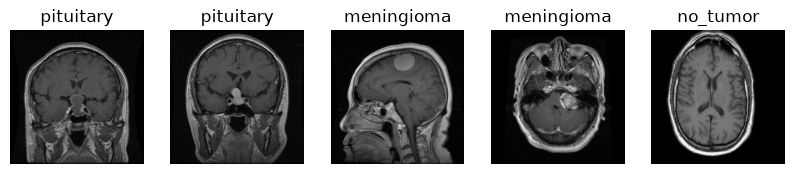

In [5]:
# want to see 5 random images from the training dataset with their labels
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(5):
        ax = plt.subplot(1, 5, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[np.argmax(labels[i])])
        plt.axis("off")
plt.show()


In [6]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dir = r"D:\ml project\brisc2025\classification_task\train"
test_dir  = r"D:\ml project\brisc2025\classification_task\test"

# Split the train folder into train/val
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    subset="training",
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    subset="validation",
    seed=SEED
)

# True held-out test set — only touch this once, at the very end
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 5000 files belonging to 4 classes.
Using 4500 files for training.
Found 5000 files belonging to 4 classes.
Using 500 files for validation.
Found 1000 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [7]:
import os

def count_classes(directory):
    counts = {}
    for cls in os.listdir(directory):
        cls_path = os.path.join(directory, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len(os.listdir(cls_path))
    return counts

train_dir = r"D:\ml project\brisc2025\classification_task\train"
test_dir  = r"D:\ml project\brisc2025\classification_task\test"

print("Train folder class counts:", count_classes(train_dir))
print("Test folder class counts:", count_classes(test_dir))

Train folder class counts: {'glioma': 1147, 'meningioma': 1329, 'no_tumor': 1067, 'pituitary': 1457}
Test folder class counts: {'glioma': 254, 'meningioma': 306, 'no_tumor': 140, 'pituitary': 300}


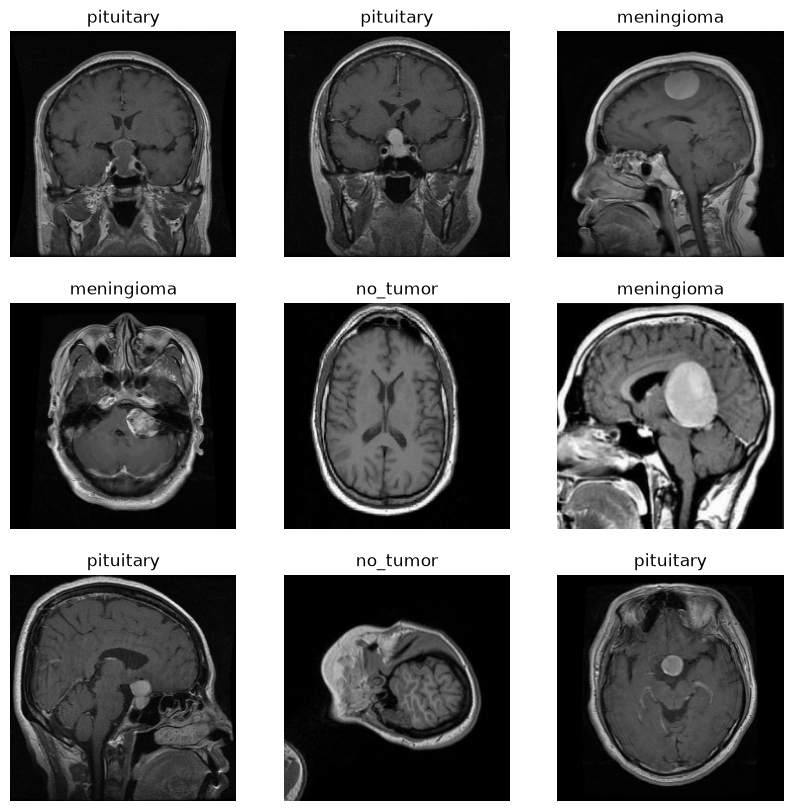

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        label_idx = tf.argmax(labels[i]).numpy()
        plt.title(class_names[label_idx])
        plt.axis("off")
plt.show()

In [9]:
for images, labels in train_ds.take(1):
    print("Batch shape:", images.shape)
    print("Pixel value range:", images.numpy().min(), "-", images.numpy().max())

Batch shape: (32, 224, 224, 3)
Pixel value range: 0.0 - 255.0


In [10]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

In [15]:
from tensorflow.keras.applications import resnet50
from tensorflow.keras import models

IMG_SHAPE = (224, 224, 3)
num_classes = len(class_names)

base_model = resnet50.ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=IMG_SHAPE
)
base_model.trainable = False  # freeze for feature extraction phase

inputs = tf.keras.Input(shape=IMG_SHAPE)
x = data_augmentation(inputs)
x = resnet50.preprocess_input(x)   # ResNet50-specific normalization
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = models.Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ data_augmentatio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 4)         │      8,196 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [17]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [18]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop]
)

Epoch 1/10


d:\ml project\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


141/141 ━━━━━━━━━━━━━━━━━━━━ 294s 2s/step - accuracy: 0.7273 - loss: 0.7038 - val_accuracy: 0.8680 - val_loss: 0.3228
Epoch 2/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 266s 2s/step - accuracy: 0.8516 - loss: 0.4112 - val_accuracy: 0.9000 - val_loss: 0.2679
Epoch 3/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 263s 2s/step - accuracy: 0.8789 - loss: 0.3487 - val_accuracy: 0.9140 - val_loss: 0.2294
Epoch 4/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 271s 2s/step - accuracy: 0.8787 - loss: 0.3175 - val_accuracy: 0.9220 - val_loss: 0.2146
Epoch 5/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 264s 2s/step - accuracy: 0.8860 - loss: 0.2889 - val_accuracy: 0.9100 - val_loss: 0.2331
Epoch 6/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 255s 2s/step - accuracy: 0.8976 - loss: 0.2802 - val_accuracy: 0.9340 - val_loss: 0.2005
Epoch 7/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 255s 2s/step - accuracy: 0.9027 - loss: 0.2620 - val_accuracy: 0.9220 - val_loss: 0.2099
Epoch 8/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 240s 2s/step - accuracy: 0.9033 - loss: 0.2535 - val_accuracy: 0.938

In [19]:
base_model.trainable = True

# Freeze everything except the last ~30 layers
fine_tune_at = len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

In [20]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ data_augmentatio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 4)         │      8,196 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 14,458,372 (55.15 MB)

 Non-trainable params: 9,137,536 (34.86 MB)

In [21]:
fine_tune_epochs = 10
total_epochs = 10 + fine_tune_epochs

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=history.epoch[-1] + 1,
    callbacks=[early_stop]
)

Epoch 11/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 410s 3s/step - accuracy: 0.8844 - loss: 0.3147 - val_accuracy: 0.9240 - val_loss: 0.2147
Epoch 12/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 441s 3s/step - accuracy: 0.9298 - loss: 0.2053 - val_accuracy: 0.9440 - val_loss: 0.1519
Epoch 13/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 368s 3s/step - accuracy: 0.9424 - loss: 0.1581 - val_accuracy: 0.9460 - val_loss: 0.1541
Epoch 14/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 375s 3s/step - accuracy: 0.9584 - loss: 0.1197 - val_accuracy: 0.9520 - val_loss: 0.1324
Epoch 15/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 354s 3s/step - accuracy: 0.9698 - loss: 0.0892 - val_accuracy: 0.9600 - val_loss: 0.1143
Epoch 16/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 312s 2s/step - accuracy: 0.9760 - loss: 0.0715 - val_accuracy: 0.9640 - val_loss: 0.1052
Epoch 17/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 395s 3s/step - accuracy: 0.9804 - loss: 0.0624 - val_accuracy: 0.9640 - val_loss: 0.1028
Epoch 18/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 365s 3s/step - accuracy: 0.9862 - loss: 0.0458 - 

In [23]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 53s 2s/step - accuracy: 0.9610 - loss: 0.1213
Test accuracy: 0.9610
Test loss: 0.1213


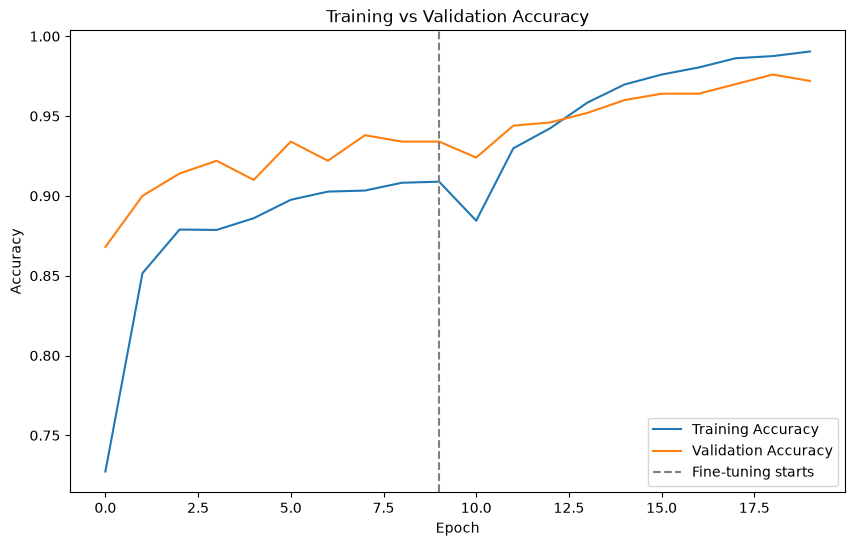

In [26]:
import matplotlib.pyplot as plt

acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']

epochs_range = range(len(acc))

plt.figure(figsize=(10, 6))
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.axvline(x=len(history.history['accuracy']) - 1, color='gray', linestyle='--', label='Fine-tuning starts')
plt.legend(loc='lower right')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.show()

In [24]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

print(classification_report(y_true, y_pred, target_names=class_names))

              precision    recall  f1-score   support

      glioma       0.98      0.92      0.95       254
  meningioma       0.95      0.94      0.95       306
    no_tumor       0.99      1.00      1.00       140
   pituitary       0.94      1.00      0.97       300

    accuracy                           0.96      1000
   macro avg       0.97      0.96      0.97      1000
weighted avg       0.96      0.96      0.96      1000



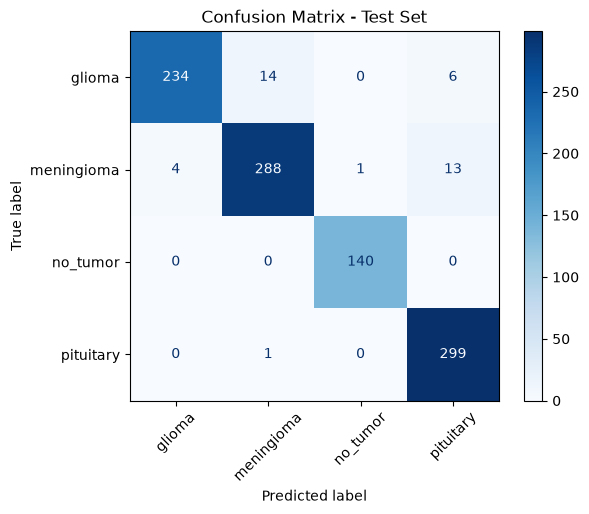

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix - Test Set")
plt.show()

In [27]:
model.save("brisc2025_resnet50_finetuned.keras")

### Training with pretrain model InceptionV3

In [14]:
IMG_SIZE = (299, 299)
BATCH_SIZE = 32
SEED = 42

train_dir = r"D:\ml project\brisc2025\classification_task\train"
test_dir  = r"D:\ml project\brisc2025\classification_task\test"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    subset="training",
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    subset="validation",
    seed=SEED
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 5000 files belonging to 4 classes.
Using 4500 files for training.
Found 5000 files belonging to 4 classes.
Using 500 files for validation.
Found 1000 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [15]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

In [16]:
from tensorflow.keras.applications import inception_v3
from tensorflow.keras import models, layers
import tensorflow as tf

IMG_SHAPE = (299, 299, 3)   # InceptionV3's native input size
num_classes = len(class_names)

base_model = inception_v3.InceptionV3(
    include_top=False,
    weights="imagenet",
    input_shape=IMG_SHAPE
)
base_model.trainable = False  # freeze for feature extraction phase

inputs = tf.keras.Input(shape=IMG_SHAPE)
x = data_augmentation(inputs)
x = inception_v3.preprocess_input(x)   # InceptionV3-specific normalization
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = models.Model(inputs, outputs)
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,810,980 (83.20 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [17]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [18]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop]
)

Epoch 1/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 306s 2s/step - accuracy: 0.6953 - loss: 0.7665 - val_accuracy: 0.8660 - val_loss: 0.4098
Epoch 2/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 305s 2s/step - accuracy: 0.8207 - loss: 0.4871 - val_accuracy: 0.8820 - val_loss: 0.3458
Epoch 3/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 305s 2s/step - accuracy: 0.8411 - loss: 0.4233 - val_accuracy: 0.8840 - val_loss: 0.3172
Epoch 4/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 321s 2s/step - accuracy: 0.8480 - loss: 0.4088 - val_accuracy: 0.8820 - val_loss: 0.3103
Epoch 5/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 313s 2s/step - accuracy: 0.8562 - loss: 0.3812 - val_accuracy: 0.8960 - val_loss: 0.2893
Epoch 6/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 305s 2s/step - accuracy: 0.8700 - loss: 0.3595 - val_accuracy: 0.9020 - val_loss: 0.2756
Epoch 7/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 265s 2s/step - accuracy: 0.8660 - loss: 0.3533 - val_accuracy: 0.9060 - val_loss: 0.2760
Epoch 8/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 272s 2s/step - accuracy: 0.8793 - loss: 0.3213 - val_accu

In [19]:
base_model.trainable = True

# Freeze everything except the last ~30 layers
fine_tune_at = len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

In [20]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,810,980 (83.20 MB)

 Trainable params: 5,164,228 (19.70 MB)

 Non-trainable params: 16,646,752 (63.50 MB)

In [21]:
fine_tune_epochs = 10
total_epochs = 10 + fine_tune_epochs

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=history.epoch[-1] + 1,
    callbacks=[early_stop]
)

Epoch 11/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 310s 2s/step - accuracy: 0.7927 - loss: 0.5513 - val_accuracy: 0.8920 - val_loss: 0.2669
Epoch 12/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 348s 2s/step - accuracy: 0.8813 - loss: 0.3408 - val_accuracy: 0.9120 - val_loss: 0.2324
Epoch 13/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 346s 2s/step - accuracy: 0.8947 - loss: 0.2947 - val_accuracy: 0.9160 - val_loss: 0.2096
Epoch 14/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 336s 2s/step - accuracy: 0.9122 - loss: 0.2506 - val_accuracy: 0.9200 - val_loss: 0.1960
Epoch 15/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 342s 2s/step - accuracy: 0.9118 - loss: 0.2412 - val_accuracy: 0.9280 - val_loss: 0.1878
Epoch 16/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 323s 2s/step - accuracy: 0.9227 - loss: 0.2170 - val_accuracy: 0.9340 - val_loss: 0.1796
Epoch 17/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 321s 2s/step - accuracy: 0.9307 - loss: 0.1993 - val_accuracy: 0.9360 - val_loss: 0.1674
Epoch 18/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 279s 2s/step - accuracy: 0.9376 - loss: 0.1910 - 

In [22]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.9190 - loss: 0.1969
Test accuracy: 0.9190
Test loss: 0.1969


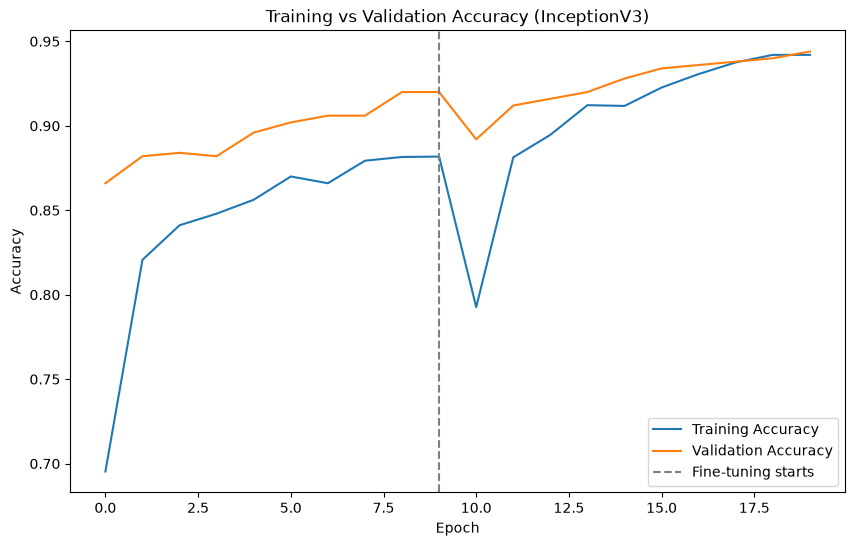

In [23]:
import matplotlib.pyplot as plt

acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']

epochs_range = range(len(acc))

plt.figure(figsize=(10, 6))
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.axvline(x=len(history.history['accuracy']) - 1, color='gray', linestyle='--', label='Fine-tuning starts')
plt.legend(loc='lower right')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy (InceptionV3)')
plt.show()

In [24]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

print(classification_report(y_true, y_pred, target_names=class_names))

              precision    recall  f1-score   support

      glioma       0.93      0.84      0.88       254
  meningioma       0.87      0.88      0.88       306
    no_tumor       0.96      1.00      0.98       140
   pituitary       0.94      0.98      0.96       300

    accuracy                           0.92      1000
   macro avg       0.92      0.93      0.93      1000
weighted avg       0.92      0.92      0.92      1000



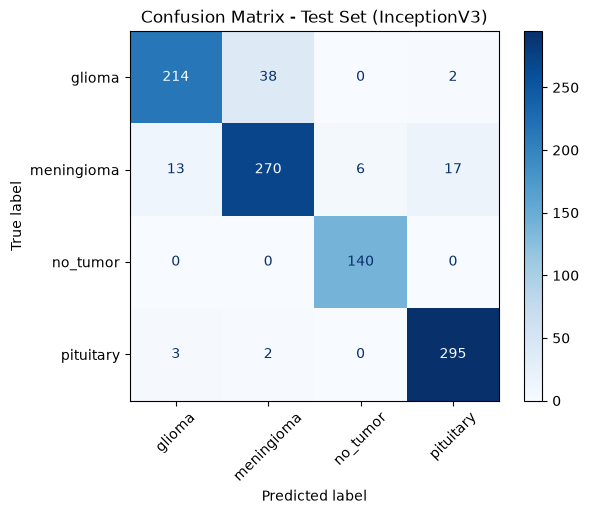

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix - Test Set (InceptionV3)")
plt.show()

In [26]:
model.save("brisc2025_inceptionv3_finetuned.keras")

### Transfer learning with VGG16

In [27]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dir = r"D:\ml project\brisc2025\classification_task\train"
test_dir  = r"D:\ml project\brisc2025\classification_task\test"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    subset="training",
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    subset="validation",
    seed=SEED
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 5000 files belonging to 4 classes.
Using 4500 files for training.
Found 5000 files belonging to 4 classes.
Using 500 files for validation.
Found 1000 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
